# Step 4: a 1D convolutional network, then all 5 categories

The MLP has a blind spot: it gives every one of its 3,000 inputs its own weight, so an MI pattern at second 2 and
the same pattern at second 6 look like completely different things to it. A **convolutional network** slides the
same small pattern detectors along the whole strip, so it finds a shape wherever it is. That's how most ECG
models (and image models) work.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ecg_common as ec

db = ec.load_labels()
X = ec.load_signals(db)
train, val, test = ec.split_masks(db)
keep, y = ec.mi_vs_normal(db)

## Getting the ECGs ready

Same standardizing as step 3, but no shrinking or flattening: the network takes the full 10 seconds, arranged as
12 leads by 1,000 time steps.

In [2]:
Xc = ec.standardize(X, train).transpose(0, 2, 1).copy()
print(Xc.shape)

(21799, 12, 1000)


## The model

`ec.ECGNet` (in `ecg_common.py`) is four blocks. Each block has detectors that look at a short window (7, then 5,
5 and 3 time steps), then halves the length, so later blocks see longer stretches of the strip: first the shape
of a wave, then a whole beat. At the end it averages over time and turns the result into a score.

In [3]:
torch.manual_seed(0)
cnn = ec.ECGNet(n_out=1)
print(f"{sum(p.numel() for p in cnn.parameters()):,} weights to learn (the MLP had about 400,000)")

104,225 weights to learn (the MLP had about 400,000)


## MI vs. normal, round 2

In [4]:
history = ec.train(cnn, Xc[train & keep], y[train & keep], Xc[val & keep], y[val & keep], epochs=20)
torch.save(cnn.state_dict(), "models/cnn_mi.pt")

epoch  1   training loss 0.294   tuning-fold AUC 0.956


epoch  2   training loss 0.225   tuning-fold AUC 0.964


epoch  3   training loss 0.203   tuning-fold AUC 0.968


epoch  4   training loss 0.196   tuning-fold AUC 0.967


epoch  5   training loss 0.188   tuning-fold AUC 0.968


epoch  6   training loss 0.169   tuning-fold AUC 0.970


... (10 outputs left out)

epoch 17   training loss 0.121   tuning-fold AUC 0.972


epoch 18   training loss 0.128   tuning-fold AUC 0.971


epoch 19   training loss 0.119   tuning-fold AUC 0.972


epoch 20   training loss 0.110   tuning-fold AUC 0.975


In [5]:
p = ec.predict(cnn, Xc[val & keep]).ravel()
y_va = y[val & keep]
print(f"tuning-fold AUC: {ec.auc(y_va, p):.3f}")
print(f"MIs caught at a 50% cut-off: {int(((p > 0.5) & (y_va == 1)).sum())} of {int(y_va.sum())}")

tuning-fold AUC: 0.975
MIs caught at a 50% cut-off: 507 of 540


## All 5 categories at once

Now the real-world version: every ECG that's in at least one category, and the network gives 5 scores at once
(normal, MI, ST/T change, conduction problem, hypertrophy). One ECG can be in several, so each score is its own
yes/no. This is the task the PTB-XL research papers report, using the average AUC over the 5 ("macro AUC").

In [6]:
has_class = (db.classes.str.len() > 0).values
Y = db[ec.CLASSES].values.astype(np.float32)
torch.manual_seed(0)
cnn5 = ec.ECGNet(n_out=5)
history5 = ec.train(cnn5, Xc[train & has_class], Y[train & has_class], Xc[val & has_class], Y[val & has_class], epochs=20)
torch.save(cnn5.state_dict(), "models/cnn_5class.pt")

epoch  1   training loss 0.374   tuning-fold AUC 0.900


epoch  2   training loss 0.299   tuning-fold AUC 0.908


epoch  3   training loss 0.283   tuning-fold AUC 0.915


epoch  4   training loss 0.274   tuning-fold AUC 0.917


epoch  5   training loss 0.268   tuning-fold AUC 0.919


epoch  6   training loss 0.260   tuning-fold AUC 0.916


... (10 outputs left out)

epoch 17   training loss 0.223   tuning-fold AUC 0.926


epoch 18   training loss 0.221   tuning-fold AUC 0.928


epoch 19   training loss 0.217   tuning-fold AUC 0.929


epoch 20   training loss 0.214   tuning-fold AUC 0.924


In [7]:
P = ec.predict(cnn5, Xc[val & has_class])
names = {"NORM": "normal", "MI": "MI", "STTC": "ST/T change", "CD": "conduction problem", "HYP": "hypertrophy"}
scores = pd.Series({names[c]: ec.auc(Y[val & has_class][:, k], P[:, k]) for k, c in enumerate(ec.CLASSES)})
print(scores.round(3).to_string())
print(f"macro AUC (tuning fold): {scores.mean():.3f}")

normal                0.944
MI                    0.932
ST/T change           0.930
conduction problem    0.931
hypertrophy           0.908
macro AUC (tuning fold): 0.929


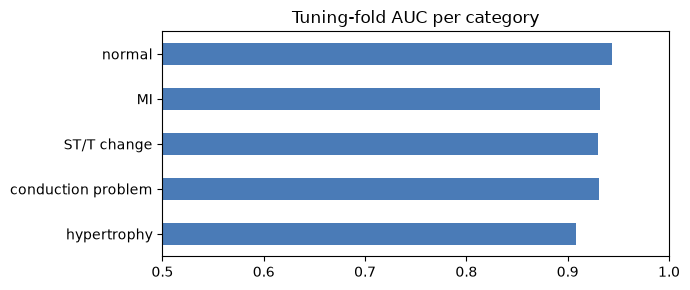

In [8]:
fig, ax = plt.subplots(figsize=(7, 3))
scores.plot.barh(ax=ax, color="#4a7bb7", xlim=(0.5, 1.0), title="Tuning-fold AUC per category")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig("figures/cnn_5class_auc.png", dpi=100, bbox_inches="tight")
plt.show()

## What this step showed

- MI vs. normal: tuning-fold AUC **0.975**, against 0.822 for the MLP and 0.813 for age alone. At a 50% cut-off it
  catches 507 of 540 MIs (94%), with about a quarter of the MLP's weights.
- Far less overfitting: the tuning AUC kept creeping up while the training loss fell, because a detector that learns
  a shape at one moment can use it everywhere in the strip.
- All 5 categories: macro AUC **0.929** on the tuning fold. Hypertrophy is the hardest (0.908), and it also has the
  fewest examples (2,649).
- MI scores lower here (0.932) than in MI vs. normal (0.975) because now an MI also has to be told apart from every
  other problem, not just from normal ECGs.